# Neural Network from Scratch (NumPy only)
A 2 layer neural network built with only NumPy: forward pass, backpropagation, gradient descent. No TensorFlow or PyTorch.



**Data:** Breast Cancer dataset that comes inside scikit-learn (no download needed). scikit-learn is used only for the data, scaling and for comparing against my network.

In [1]:
!pip install -q numpy scikit-learn matplotlib

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
X = data.data
y = data.target.reshape(-1, 1)
print("shape:", X.shape, " classes:", np.unique(y, return_counts=True))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("majority baseline accuracy:", round(max(y_test.mean(), 1 - y_test.mean()), 4))

shape: (569, 30)  classes: (array([0, 1]), array([212, 357]))
majority baseline accuracy: 0.6316


In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def start_weights(n_in, n_hidden):
    np.random.seed(1)
    w1 = np.random.randn(n_in, n_hidden) * 0.1
    b1 = np.zeros((1, n_hidden))
    w2 = np.random.randn(n_hidden, 1) * 0.1
    b2 = np.zeros((1, 1))
    return w1, b1, w2, b2

def forward(X, w1, b1, w2, b2):
    z1 = X.dot(w1) + b1
    a1 = np.tanh(z1)
    z2 = a1.dot(w2) + b2
    a2 = sigmoid(z2)
    return a1, a2

def get_loss(y, a2):
    e = 1e-8
    return -np.mean(y * np.log(a2 + e) + (1 - y) * np.log(1 - a2 + e))

def backward(X, y, a1, a2, w2):
    m = X.shape[0]
    dz2 = a2 - y
    dw2 = a1.T.dot(dz2) / m
    db2 = np.sum(dz2, axis=0, keepdims=True) / m
    dz1 = dz2.dot(w2.T) * (1 - a1 ** 2)
    dw1 = X.T.dot(dz1) / m
    db1 = np.sum(dz1, axis=0, keepdims=True) / m
    return dw1, db1, dw2, db2

In [4]:
# checking backprop with a numerical gradient on a small piece of data
w1, b1, w2, b2 = start_weights(X_train.shape[1], 8)
xs = X_train[:20]
ys = y_train[:20]
a1, a2 = forward(xs, w1, b1, w2, b2)
dw1, db1, dw2, db2 = backward(xs, ys, a1, a2, w2)

eps = 1e-5
max_diff = 0
for i in range(3):
    for j in range(3):
        w1[i, j] += eps
        loss_plus = get_loss(ys, forward(xs, w1, b1, w2, b2)[1])
        w1[i, j] -= 2 * eps
        loss_minus = get_loss(ys, forward(xs, w1, b1, w2, b2)[1])
        w1[i, j] += eps
        num_grad = (loss_plus - loss_minus) / (2 * eps)
        diff = abs(num_grad - dw1[i, j])
        max_diff = max(max_diff, diff)
print("biggest gradient difference:", max_diff)
if max_diff < 1e-6:
    print("gradient check passed")
else:
    print("gradient check FAILED, something is wrong in backward()")

biggest gradient difference: 2.9408251875362446e-10
gradient check passed


In [5]:
def train_network(X, y, X_val, y_val, n_hidden=16, lr=0.1, epochs=1000):
    w1, b1, w2, b2 = start_weights(X.shape[1], n_hidden)
    train_losses = []
    val_losses = []
    for epoch in range(epochs):
        a1, a2 = forward(X, w1, b1, w2, b2)
        dw1, db1, dw2, db2 = backward(X, y, a1, a2, w2)
        w1 = w1 - lr * dw1
        b1 = b1 - lr * db1
        w2 = w2 - lr * dw2
        b2 = b2 - lr * db2
        train_losses.append(get_loss(y, a2))
        val_losses.append(get_loss(y_val, forward(X_val, w1, b1, w2, b2)[1]))
        if epoch % 100 == 0:
            print("epoch", epoch, "train loss", round(train_losses[-1], 4), "val loss", round(val_losses[-1], 4))
    return (w1, b1, w2, b2), train_losses, val_losses

params, train_losses, val_losses = train_network(X_train, y_train, X_test, y_test)

epoch 0 train loss 0.7533 val loss 0.7176
epoch 100 train loss 0.0839 val loss 0.1071
epoch 200 train loss 0.062 val loss 0.09
epoch 300 train loss 0.0547 val loss 0.0855
epoch 400 train loss 0.0507 val loss 0.0838
epoch 500 train loss 0.0481 val loss 0.0832
epoch 600 train loss 0.0461 val loss 0.0833
epoch 700 train loss 0.0445 val loss 0.0837
epoch 800 train loss 0.0432 val loss 0.0841
epoch 900 train loss 0.042 val loss 0.0846


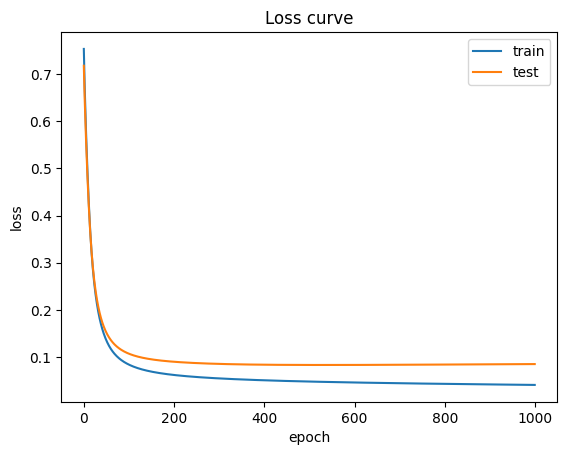

my network train accuracy: 0.9912
my network test accuracy: 0.9561


In [6]:
plt.plot(train_losses, label="train")
plt.plot(val_losses, label="test")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Loss curve")
plt.legend()
plt.show()

w1, b1, w2, b2 = params
train_pred = (forward(X_train, *params)[1] > 0.5).astype(int)
test_pred = (forward(X_test, *params)[1] > 0.5).astype(int)
my_train_acc = (train_pred == y_train).mean()
my_test_acc = (test_pred == y_test).mean()
print("my network train accuracy:", round(my_train_acc, 4))
print("my network test accuracy:", round(my_test_acc, 4))

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, classification_report

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train.ravel())
lr_acc = lr_model.score(X_test, y_test.ravel())

mlp = MLPClassifier(hidden_layer_sizes=(16,), activation="tanh", max_iter=1000, random_state=1)
mlp.fit(X_train, y_train.ravel())
mlp_acc = mlp.score(X_test, y_test.ravel())

print("Logistic Regression test accuracy:", round(lr_acc, 4))
print("sklearn MLP test accuracy:", round(mlp_acc, 4))
print("My NumPy network test accuracy:", round(my_test_acc, 4))
print()
print(confusion_matrix(y_test, test_pred))
print(classification_report(y_test, test_pred, target_names=data.target_names))

Logistic Regression test accuracy: 0.9825
sklearn MLP test accuracy: 0.9561
My NumPy network test accuracy: 0.9561

[[41  1]
 [ 4 68]]
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



In [8]:
results = {}
for hidden in [2, 4, 8, 16, 32]:
    w1_, b1_, w2_, b2_ = start_weights(X_train.shape[1], hidden)
    for epoch in range(1000):
        a1_, a2_ = forward(X_train, w1_, b1_, w2_, b2_)
        g1, gb1, g2, gb2 = backward(X_train, y_train, a1_, a2_, w2_)
        w1_ -= 0.1 * g1
        b1_ -= 0.1 * gb1
        w2_ -= 0.1 * g2
        b2_ -= 0.1 * gb2
    acc = ((forward(X_test, w1_, b1_, w2_, b2_)[1] > 0.5).astype(int) == y_test).mean()
    results[hidden] = round(acc, 4)

print("test accuracy by hidden layer size:", results)

test accuracy by hidden layer size: {2: np.float64(0.9561), 4: np.float64(0.9561), 8: np.float64(0.9474), 16: np.float64(0.9561), 32: np.float64(0.9474)}


In [ ]:

# ============================================================
# UNIVERSAL COLAB PROJECT AUTO-SAVE
# Structure: Parent Folder / Notebook Name / All Project Files
# ============================================================

import os
import json
import shutil
from pathlib import Path
from google.colab import auth, _message
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload
from google.auth import default

# 1. DESTINATION GOOGLE DRIVE FOLDER
PARENT_FOLDER_ID = "1RJ_KbIui8TyupB2kr3c-N93lt2OE0nAk"

# 2. AUTHENTICATE
auth.authenticate_user()
credentials, _ = default()
drive = build("drive", "v3", credentials=credentials)

# 3. DETECT CURRENT NOTEBOOK
notebook_data = _message.blocking_request("get_ipynb")

if "ipynb" in notebook_data:
    notebook_data = notebook_data["ipynb"]

project_name = (
    notebook_data.get("metadata", {})
    .get("colab", {})
    .get("name", "")
)

if not project_name:
    project_name = input("Enter your Colab notebook name (e.g. RAG): ").strip()

project_name = Path(project_name).stem

if not project_name:
    raise ValueError("Project name is missing.")

print("Project detected:", project_name)

# 4. FIND OR CREATE PROJECT FOLDER
query = (
    f"'{PARENT_FOLDER_ID}' in parents "
    f"and name = '{project_name}' "
    "and mimeType = 'application/vnd.google-apps.folder' "
    "and trashed = false"
)

results = drive.files().list(
    q=query,
    fields="files(id,name)",
    supportsAllDrives=True,
    includeItemsFromAllDrives=True
).execute()

if results.get("files"):
    PROJECT_FOLDER_ID = results["files"][0]["id"]
else:
    folder = drive.files().create(
        body={
            "name": project_name,
            "mimeType": "application/vnd.google-apps.folder",
            "parents": [PARENT_FOLDER_ID]
        },
        fields="id"
    ).execute()

    PROJECT_FOLDER_ID = folder["id"]

# 5. UPLOAD FILES WITHOUT ZIP
SKIP_DIRS = {
    "drive", "sample_data", ".config",
    ".cache", "__pycache__"
}

uploaded = 0
failed = []

def find_existing_file(name, parent_id):
    q = (
        f"'{parent_id}' in parents "
        f"and name = '{name}' "
        "and trashed = false"
    )
    found = drive.files().list(
        q=q,
        fields="files(id)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True
    ).execute()
    return found.get("files", [])

def upload_file(local_path, parent_id):
    global uploaded

    filename = os.path.basename(local_path)

    metadata = {
        "name": filename,
        "parents": [parent_id]
    }

    media = MediaFileUpload(
        local_path,
        resumable=True
    )

    existing = find_existing_file(filename, parent_id)

    if existing:
        drive.files().update(
            fileId=existing[0]["id"],
            media_body=media,
            supportsAllDrives=True
        ).execute()
    else:
        drive.files().create(
            body=metadata,
            media_body=media,
            fields="id",
            supportsAllDrives=True
        ).execute()

    uploaded += 1
    print("Saved:", filename)

def upload_directory(local_dir, drive_parent_id):
    for item in os.scandir(local_dir):

        if item.is_dir(follow_symlinks=False):

            if item.name in SKIP_DIRS:
                continue

            existing = find_existing_file(
                item.name, drive_parent_id
            )

            if existing:
                subfolder_id = existing[0]["id"]
            else:
                result = drive.files().create(
                    body={
                        "name": item.name,
                        "mimeType": "application/vnd.google-apps.folder",
                        "parents": [drive_parent_id]
                    },
                    fields="id",
                    supportsAllDrives=True
                ).execute()
                subfolder_id = result["id"]

            upload_directory(item.path, subfolder_id)

        elif item.is_file(follow_symlinks=False):
            try:
                upload_file(item.path, drive_parent_id)
            except Exception as error:
                failed.append((item.name, str(error)))
                print("Upload failed:", item.name, error)

# 6. SAVE EXECUTED NOTEBOOK
notebook_path = f"/content/{project_name}.ipynb"

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook_data, f, ensure_ascii=False, indent=2)

# 7. UPLOAD PROJECT FILES
upload_directory("/content", PROJECT_FOLDER_ID)

# 8. FINAL REPORT
print("\n======================================")
print("PROJECT BACKUP COMPLETED")
print("======================================")
print("Project:", project_name)
print("Uploaded files:", uploaded)
print("Failed files:", len(failed))
print(
    "Folder:",
    f"https://drive.google.com/drive/folders/{PROJECT_FOLDER_ID}"
)

if failed:
    print("\nFailed uploads:")
    for name, error in failed:
        print(name, error)